# TouNum, deliverable 3: automatic image captioning and the complete workflow

CESI Data Science team. Prototype of the automatic image captioning workflow.

---
## 0. Business context and goal

TouNum digitises documents for its clients and wants to sell an automatic captioning service: for every photo
in a digitised archive, a short sentence that describes it, so the archive can be searched by content. The
workflow has three modules:

1. Filtering: keep only the photos (deliverable 1);
2. Pre-processing: remove the noise from the photos that need it (deliverable 2);
3. **Captioning: write a caption for each photo (this deliverable)**.

The captioning model follows the approach given in the brief. A convolutional network (CNN), pre-trained for
image classification, turns each image into a set of feature vectors. A recurrent network (RNN) then writes the
caption one word at a time, each word depending on the image and on the words already written. The model is
trained on MS COCO, a public dataset of photos with five captions each, written by people.

The last part of the notebook assembles the three deliverables into one workflow that takes a folder of images
and returns a table of captions. Its final cell is the one to run on presentation day, on a new folder.

### Outline
| Section | Content |
|---|---|
| 1 | Environment |
| 2 | The MS COCO data: sampling, download, examples |
| 3 | Text pre-processing: cleaning, vocabulary, encoding |
| 4 | Image pre-processing with a pre-trained CNN (InceptionV3) |
| 5 | Captioning model: architecture, loss, optimiser |
| 6 | Training and learning curves, with and without attention |
| 7 | Evaluation on the test images: BLEU scores, examples, attention maps |
| 8 | Case study: noisy photos, denoising and caption quality |
| 9 | The complete workflow (deliverables 1, 2 and 3) on a demo folder |
| 10 | Conclusion, limits, and the cell to run on a new folder |

### How to run it
`bash scripts/run_notebook.sh 3 full` rebuilds the `.ipynb` from this `.py` file and runs it. It needs an
internet connection on the first run (COCO captions and images, ImageNet weights of InceptionV3) and the saved
models of deliverables 1 and 2 (`models/photo_classifier.keras`, `models/denoiser.keras`). The image features are
computed once and cached in `data/features/`. `bash scripts/run_notebook.sh 3 quick` runs a very short version on
a few hundred images to check that everything executes; it never touches the deliverable or the saved models.

## 1. Environment

In [1]:
import os
import sys
import json
import time
import shutil
import inspect
import tempfile
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")      # hide TensorFlow C++ logs (GPU autotuning notices)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import tounum_gpu
tounum_gpu.setup()                                      # use the NVIDIA GPU if there is one (src/tounum_gpu.py)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display, Markdown
import tensorflow as tf
import keras

from tounum_cls import config as cls_config, data as cls_data
from tounum_denoise import config as dn_config, data as dn_data, modeling as dn_modeling
from tounum_caption import config, data, features, model, evaluation, pipeline

QUICK = os.environ.get("TOUNUM_QUICK") == "1"
EPOCHS = 2 if QUICK else 60                 # upper bound: early stopping decides when to stop
PATIENCE = 6
SIZES = {"train": 2_000, "val": 300, "test": 300} if QUICK else None    # QUICK: a few images per split
N_BLEU_EPOCH = 300 if QUICK else 500        # validation images captioned at the end of every epoch
N_CASE = 100 if QUICK else 1_000            # test images used in the case study (section 8)
LOADER = dict(workers=8, use_multiprocessing=False)   # 8 threads prepare the batches while the GPU trains
SAVE_DIR = Path(tempfile.gettempdir()) / "tounum_quick" if QUICK else config.MODELS_DIR   # QUICK never touches models/
FEATURES_DIR = SAVE_DIR / "features" if QUICK else config.FEATURES_DIR
SPLITS = ("train", "val", "test")
if QUICK:
    os.environ["TOUNUM_MODELS_DIR"] = str(SAVE_DIR)     # read by the last cell of the notebook

keras.utils.set_random_seed(config.SEED)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 90)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

print(f"Python {sys.version.split()[0]} | TensorFlow {tf.__version__} | Keras {keras.__version__} | numpy {np.__version__}")
print("GPU:", tf.config.list_physical_devices("GPU") or "none (running on CPU)")
print(f"Seed: {config.SEED} | QUICK mode: {QUICK} | max epochs: {EPOCHS}")

I0000 00:00:1791318133.516511 2594557 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791318134.052105 2594557 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python 3.12.13 | TensorFlow 2.21.0 | Keras 3.15.1 | numpy 2.5.3
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Seed: 42 | QUICK mode: False | max epochs: 60


## 2. The MS COCO data

MS COCO 2017 has about 118,000 training images and 5,000 validation images, everyday scenes with people,
animals, vehicles and objects. Each image comes with five captions written by different people. We use a sample:

| Split | Source | Images | Role |
|---|---|---|---|
| `train` | COCO `train2017` | 80,000 drawn at random | learn the weights |
| `val` | COCO `train2017`, no overlap with `train` | 2,000 | follow training, early stopping, choice of the model |
| `test` | COCO `val2017` | 2,000 | final measurement only |

The images are downloaded one by one from the COCO server (`data.download_images`), which avoids the 18 GB
archive. A first version used 28,000 training images, a size meant for a CPU. Training now runs on a GPU, where
more images cost little time, and the learning curve of section 6.1 shows how the scores change with the number
of training images. We therefore use 80,000 images (about 400,000 captions). Going further is possible, but every
10,000 extra images add 2.6 GB of image features to keep in memory.

The 148 noisy photos of deliverable 2 are COCO training images (their clean originals were found in
deliverable 2). Some of them fall in our sample. They are removed from it, so that the case study of section 8 and
the demo of section 9 run on images the captioning model has never seen.

In [2]:
t0 = time.perf_counter()
data.download_annotations()
images = data.sample_images()
originals = pd.read_csv(dn_config.ORIGINALS_CSV)
n_sampled = len(images)
images = data.exclude_images(images, originals["coco_id"])
n_excluded = n_sampled - len(images)
if QUICK:
    images = images[images.groupby("split").cumcount() < images["split"].map(SIZES)].reset_index(drop=True)
failed = data.download_images(images)
assert not failed, f"{len(failed)} images could not be downloaded"
captions = data.captions_for(images)

table = pd.DataFrame({"images": images["split"].value_counts(), "captions": captions["split"].value_counts()}).loc[list(SPLITS)]
table["captions per image"] = table["captions"] / table["images"]
display(table)
print(f"{n_excluded} sampled images removed (clean originals of the deliverable 2 noisy photos) | "
      f"ready in {time.perf_counter() - t0:.0f} s")

,images,captions,captions per image
split,,,
train,79901,399713,5.003
val,1997,9986,5.001
test,2000,10005,5.003


102 sampled images removed (clean originals of the deliverable 2 noisy photos) | ready in 8 s


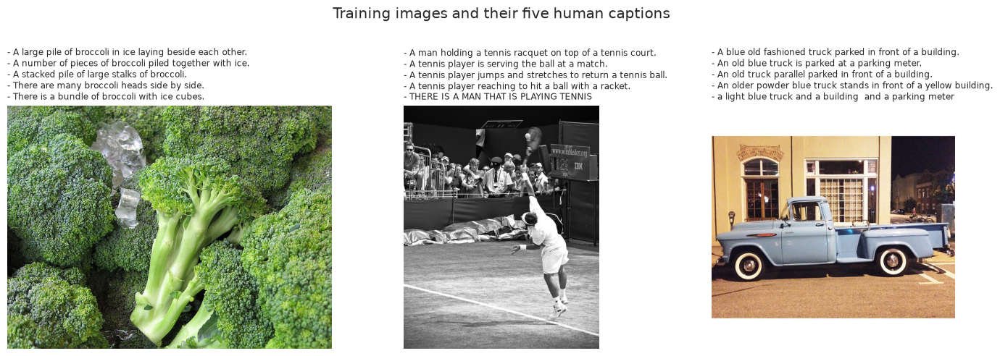

In [3]:
shown = images[images["split"] == "train"].sample(3, random_state=config.SEED)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.9))
for ax, (_, row) in zip(axes, shown.iterrows()):
    ax.imshow(cls_data.read_rgb(row["path"]))
    ax.axis("off")
    caps = captions.loc[captions["image_id"] == row["image_id"], "caption"].tolist()
    ax.set_title("\n".join(f"- {c.strip()}" for c in caps), fontsize=8.5, loc="left")
plt.suptitle("Training images and their five human captions", y=1.0)
plt.tight_layout()
plt.show()

The five captions of an image describe the same scene with different words and different details. This matters
for evaluation: a generated caption is compared with all five (section 7), since there is no single right answer.

## 3. Text pre-processing

The captions go through three steps before the network sees them:

1. **Cleaning** (`data.clean_caption`): lower case, letters only (punctuation and digits removed), and two
   markers added, `startseq` at the beginning and `endseq` at the end. `startseq` is the first input of the
   decoder; generating `endseq` is how the model says the caption is finished.
2. **Vocabulary** (`data.build_vocabulary`): the 5,000 most frequent words of the *training* captions. Index 0
   is reserved for padding and index 1 for unknown words (`[UNK]`), which replace the rare words.
3. **Encoding** (`data.encode`): each caption becomes a fixed-length sequence of 22 word indices, padded with
   zeros. Longer captions are cut but keep their `endseq`.

In [4]:
ex = captions.sample(4, random_state=config.SEED)
display(pd.DataFrame({"raw caption": ex["caption"].str.strip().to_numpy(), "cleaned": ex["clean"].to_numpy()}))

vocab = data.build_vocabulary(captions.loc[captions["split"] == "train", "clean"])
word_counts = pd.Series(Counter(" ".join(captions.loc[captions["split"] == "train", "clean"]).split()))
word_counts = word_counts.drop([config.START, config.END])          # the markers are not words
coverage = word_counts[word_counts.index.isin(set(vocab))].sum() / word_counts.sum()
lengths = captions["clean"].str.split().str.len()
fits = (lengths <= config.MAX_LEN).mean()

tokens = {s: data.encode(captions.loc[captions["split"] == s, "clean"], vocab) for s in SPLITS}
image_index = {s: captions.loc[captions["split"] == s, "image_index"].to_numpy() for s in SPLITS}
refs = {s: data.references(captions, s) for s in SPLITS}

sample = ex["clean"].iloc[0]
ids = data.encode([sample], vocab)[0]
print(f"'{sample}'\n-> {ids.tolist()}\n-> back to text: '{data.decode(ids, vocab)}'")

,raw caption,cleaned
0,"Blue and pink, and white frosted cupcakes with on a plate.",startseq blue and pink and white frosted cupcakes with on a plate endseq
1,A plate with a very bright colored decorated cake.,startseq a plate with a very bright colored decorated cake endseq
2,A group of people riding skis across a snow covered slope.,startseq a group of people riding skis across a snow covered slope endseq
3,A person in a boat on the shore of a beach while another person stands outside it.,startseq a person in a boat on the shore of a beach while another person stands outsid...


'startseq blue and pink and white frosted cupcakes with on a plate endseq'
-> [4, 60, 10, 262, 10, 22, 1301, 1293, 9, 5, 2, 43, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0]
-> back to text: 'blue and pink and white frosted cupcakes with on a plate'


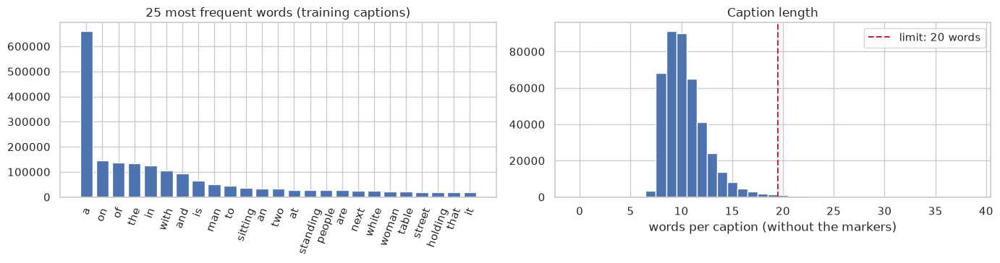

**Results.** The training captions use **22,431** distinct words. The vocabulary keeps 4,996 of them (plus padding, `[UNK]` and the two markers), which cover **98.7%** of the word occurrences: the other words are rare (names, typos) and become `[UNK]`. **99.4%** of the captions fit in 22 tokens without being cut. The median caption has 10 words.

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
top = word_counts.nlargest(25)
axes[0].bar(top.index, top.to_numpy())
axes[0].tick_params(axis="x", rotation=70)
axes[0].set_title("25 most frequent words (training captions)")
axes[1].hist(lengths - 2, bins=np.arange(0, 40) - 0.5)
axes[1].axvline(config.MAX_LEN - 2.5, color="tab:red", ls="--", label=f"limit: {config.MAX_LEN - 2} words")
axes[1].set_xlabel("words per caption (without the markers)")
axes[1].set_title("Caption length")
axes[1].legend()
plt.tight_layout()
plt.show()

display(Markdown(
    f"**Results.** The training captions use **{len(word_counts):,}** distinct words. The vocabulary keeps "
    f"{len(vocab) - 4:,} of them (plus padding, `[UNK]` and the two markers), which cover **{coverage:.1%}** of the "
    "word occurrences: the other words are rare (names, typos) and become `[UNK]`. "
    f"**{fits:.1%}** of the captions fit in {config.MAX_LEN} tokens without being cut. The median caption has "
    f"{int(np.median(lengths - 2))} words."
))

## 4. Image pre-processing with a pre-trained CNN

The brief asks for images to be pre-processed by a CNN pre-trained for classification. We use **InceptionV3**,
trained on ImageNet (1.2 million images, 1,000 classes). Its convolutional layers have learned to detect edges,
textures, object parts and whole objects, which is what a caption needs. We remove its classification head and
keep the output of its last convolutional block: an 8 x 8 grid of 2,048 features. Each of the 64 cells describes
one region of the image, which lets the decoder look at different regions for different words (section 5).

Image pre-processing steps, all inside `features.py`:
1. read the file with ImageIO as RGB (grayscale and RGBA images are converted, as in deliverable 1);
2. resize to 299 x 299 pixels, the input size of InceptionV3 (the aspect ratio is not kept);
3. scale the pixels from [0, 255] to [-1, 1], the range InceptionV3 was trained with (inside the model);
4. run the frozen network and flatten the 8 x 8 x 2048 output into 64 vectors of 2,048 values.

InceptionV3 is frozen: its 21.8 million weights are not trained here. The features of each image are therefore
always the same, so they are computed once and stored on disk (as 16-bit floats, which halves the size).
Training then only reads these files, which makes every epoch much faster.

In [6]:
print(inspect.getsource(features.build_encoder))
encoder = features.build_encoder()
encoder.summary()

def build_encoder(weights: str | None = "imagenet") -> keras.Model:
    """Frozen InceptionV3 without its classification head.

    Input: uint8 RGB images (299, 299, 3); the [-1, 1] scaling InceptionV3 expects is done inside the model.
    Output: (64, 2048) float32, the 8 x 8 grid of the last convolutional block flattened into 64 regions.
    `weights=None` (tests) avoids downloading the ImageNet weights.
    """
    size = config.FEATURE_IMG_SIZE
    base = keras.applications.InceptionV3(include_top=False, weights=weights, input_shape=(size, size, 3))
    base.trainable = False
    inputs = keras.Input(shape=(size, size, 3), name="image")
    x = layers.Rescaling(1.0 / 127.5, offset=-1.0, name="rescaling")(inputs)
    x = base(x, training=False)
    outputs = layers.Reshape((config.N_REGIONS, config.FEATURE_DIM), name="regions")(x)
    return keras.Model(inputs, outputs, name="inceptionv3_encoder")



Model: "inceptionv3_encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 8, 8, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regions (Reshape)               │ (None, 64, 2048)       │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,802,784 (83.17 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 21,802,784 (83.17 MB)

In [7]:
feats = {}
for s in SPLITS:
    t0 = time.perf_counter()
    cached = (FEATURES_DIR / f"{s}.npy").exists()
    feats[s] = features.extract_features(encoder, images.loc[images["split"] == s, "path"], FEATURES_DIR / f"{s}.npy")
    print(f"{s}: features {feats[s].shape}, {feats[s].nbytes / 1e9:.2f} GB, "
          + (f"read from the cache in {time.perf_counter() - t0:.0f} s" if cached else
             f"computed in {time.perf_counter() - t0:.0f} s"))

train: features (79901, 64, 2048), 20.95 GB, read from the cache in 3 s
val: features (1997, 64, 2048), 0.52 GB, read from the cache in 0 s
test: features (2000, 64, 2048), 0.52 GB, read from the cache in 0 s


To see what the pre-trained network already knows, we run the full InceptionV3, with its ImageNet classification
head, on a few test images (prepared exactly as above) and show its three most likely ImageNet classes. Our
encoder is this same network without the last layers: its features carry this knowledge of objects. ImageNet only
has object classes, so the network can name an object but cannot describe a scene or an action: that is the job
of the decoder.

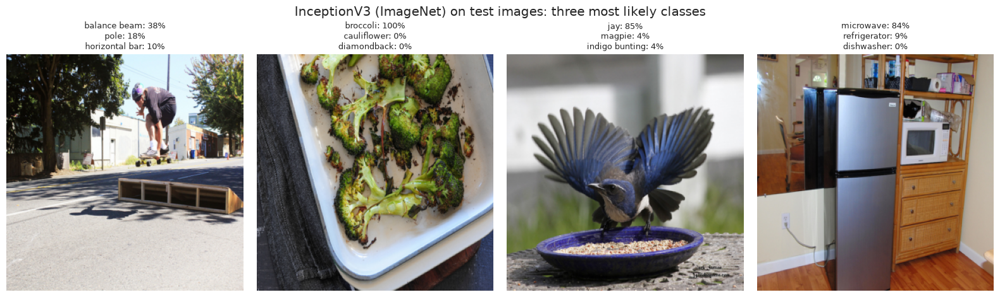

**Results.** InceptionV3 turns each image into 64 vectors of 2048 values. The features of the 83,898 images take 22.0 GB on disk and in memory.

In [8]:
imagenet_cnn = keras.applications.InceptionV3(weights="imagenet")
shown_test = images[images["split"] == "test"].head(4)
batch = np.stack([features.load_image(p) for p in shown_test["path"]])
top3 = keras.applications.inception_v3.decode_predictions(
    imagenet_cnn.predict(keras.applications.inception_v3.preprocess_input(batch.astype("float32")), verbose=0), top=3)
fig, axes = plt.subplots(1, 4, figsize=(16, 4.6))
for ax, img, preds in zip(axes, batch, top3):
    ax.imshow(img)
    ax.set_title("\n".join(f"{name.replace('_', ' ')}: {p:.0%}" for _, name, p in preds), fontsize=9)
    ax.axis("off")
plt.suptitle("InceptionV3 (ImageNet) on test images: three most likely classes", y=1.02)
plt.tight_layout()
plt.show()
del imagenet_cnn

display(Markdown(
    f"**Results.** InceptionV3 turns each image into {config.N_REGIONS} vectors of {config.FEATURE_DIM} values. "
    f"The features of the {sum(len(f) for f in feats.values()):,} images take "
    f"{sum(f.nbytes for f in feats.values()) / 1e9:.1f} GB on disk and in memory."
))

## 5. Captioning model

### 5.1 Architecture

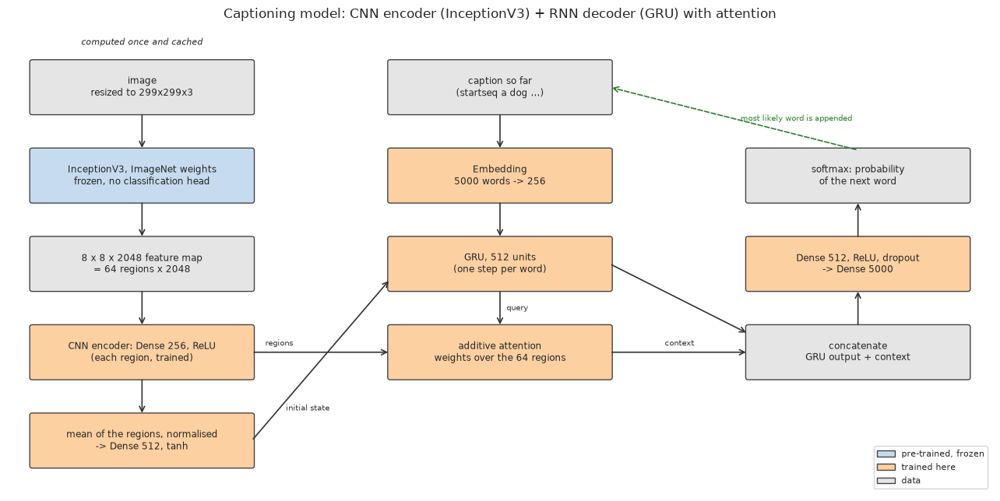

In [9]:
evaluation.draw_architecture(vocab_size=len(vocab))
plt.show()

The model has a CNN part and an RNN part, as asked in the brief:

- **CNN part.** InceptionV3 (frozen, section 4) followed by a trainable `Dense(256, ReLU)` layer applied to each
  of the 64 regions. This projection adapts the ImageNet features to the captioning task. The mean of the
  projected regions, normalised (`LayerNormalization`) and passed through `Dense(512, tanh)`, gives the initial
  state of the RNN: the decoder starts with a summary of the whole image. The normalisation keeps the `tanh` away
  from saturation; without it, a first version sometimes ended up giving every image the same initial state.
- **RNN part.** The words written so far go through an `Embedding` layer (each word becomes a vector of 256
  values, learned during training) and a **GRU** layer of 512 units. A GRU is a recurrent layer with gates that
  decide what to keep from previous words; it does the same job as an LSTM with fewer parameters.
- **Attention.** At every step, the GRU output is compared with each of the 64 regions (additive, or Bahdanau,
  attention). The scores go through a softmax, which gives 64 weights that sum to 1, and the weighted sum of the
  regions (the *context*) tells the model where to look for the next word. Without attention, the image would
  only enter through the initial state and the decoder would have to remember it for the whole sentence.
- **Output.** The GRU output and the context are concatenated, go through `Dense(512, ReLU)` and dropout, and a
  last `Dense` layer gives one score per vocabulary word. A softmax turns the scores into the probability of
  each word being the next one.

The code below is the one used for training (`src/tounum_caption/model.py`). The model only uses built-in Keras
layers, so the saved file can be loaded without any custom code.

In [10]:
print(inspect.getsource(model.build_captioner))
keras.utils.set_random_seed(config.SEED)
captioner = model.build_captioner(vocab_size=len(vocab))
captioner.summary()

def build_captioner(
    vocab_size: int = config.VOCAB_SIZE,
    attention: bool = True,
    embed_dim: int = config.EMBED_DIM,
    units: int = config.UNITS,
    dropout: float = 0.3,
    learning_rate: float = 1e-3,
    name: str | None = None,
) -> keras.Model:
    """Caption decoder trained with teacher forcing: predicts word t+1 from the image and words 1..t.

    Inputs: `image_features` (64, 2048), the InceptionV3 regions, and `tokens` (T,), the caption so far.
    Output: logits (T, vocab_size) for the next word at each position.
    CNN side: a trainable Dense layer projects each region to `embed_dim`; their mean, normalised, gives the initial
    GRU state. Without the normalisation the tanh of the initial state can saturate early in training: every image
    then gets the same state and the model without attention ignores the image.
    RNN side: Embedding -> GRU. With `attention=True`, at every step the GRU output looks at the 64 projected
    regions (additive attention) 

Model: "captioner_attention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_features      │ (None, 64, 2048)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_encoder (Dense) │ (None, 64, 256)   │    524,544 │ image_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tokens (InputLayer) │ (None, None)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_mean          │ (None, 256)       │          0 │ cnn_encoder[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, None, 256) │  1,280,000 │ tokens[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_norm          │ (None, 256)       │        512 │ image_mean[0][0]  │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_dropout   │ (None, None, 256) │          0 │ embedding[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ initial_state       │ (None, 512)       │    131,584 │ image_norm[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, None, 512) │  1,182,720 │ embedding_dropou… │
│                     │                   │            │ initial_state[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_query     │ (None, None, 256) │    131,328 │ gru[0][0]         │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ [(None, None,     │        256 │ attention_query[… │
│ (AdditiveAttention) │ 256), (None,      │            │ cnn_encoder[0][0] │
│                     │ None, 64)]        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_and_context     │ (None, None, 768) │          0 │ gru[0][0],        │
│ (Concatenate)       │                   │            │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ hidden (Dense)      │ (None, None, 512) │    393,728 │ gru_and_context[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ hidden_dropout      │ (None, None, 512) │          0 │ hidden[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ next_word (Dense)   │ (None, None,      │  2,565,000 │ hidden_dropout[0… │
│                     │ 5000)             │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,209,672 (23.69 MB)

 Trainable params: 6,209,672 (23.69 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
parts = {"CNN part (projection, initial state)": ["cnn_encoder", "image_norm", "initial_state"],
         "RNN part (embedding, GRU)": ["embedding", "gru"],
         "attention": ["attention_query", "attention"],
         "output layers": ["hidden", "next_word"]}
param_table = pd.DataFrame({"parameters": {k: sum(captioner.get_layer(n).count_params() for n in v) for k, v in parts.items()}})
param_table["share"] = param_table["parameters"] / param_table["parameters"].sum()
display(param_table)

,parameters,share
"CNN part (projection, initial state)",656640,0.106
"RNN part (embedding, GRU)",2462720,0.397
attention,131584,0.021
output layers,2958728,0.476


### 5.2 Training: teacher forcing, loss and optimiser

| Item | Choice | Why |
|---|---|---|
| Inputs / targets | the caption without its last token / the caption without its first token | at every position the model learns to predict the next word (**teacher forcing**: during training it always receives the true previous words) |
| **Loss** | sparse categorical cross-entropy on the next word, averaged over the real words (padding ignored) | it is $-\log p(\text{correct next word})$: low when the model gives a high probability to the word the person wrote |
| **Optimiser** | **Adam**, learning rate $10^{-3}$, gradient norm clipped at 5 | reliable default; clipping avoids the occasional very large gradient of recurrent networks |
| Batches | 64 captions; one caption per image per epoch, drawn again at each epoch | epochs stay short and all five captions are seen over the epochs |
| Regularisation | dropout 0.3 on the word vectors and before the output, early stopping on the validation loss (patience 6, best weights restored) | limits overfitting |
| Tracked metrics | next-word accuracy (padding ignored) and, at the end of each epoch, BLEU-4 on 500 validation images | the loss measures single words; BLEU measures whole generated captions |

**Generating a caption** (`model.generate`): start with `startseq`, ask the model for the probabilities of the
next word, keep the most likely one (*greedy decoding*), append it and repeat until `endseq` or 20 words. The
model never sees the true caption at this stage, so its own mistakes can add up; this is the main difference
between training and use. Padding and `[UNK]` are never chosen, since a caption with an unknown word is useless.

## 6. Training and learning curves

We train two versions with the same data, seed and settings: the model with attention described above, and the
same model **without attention** (the image only enters through the initial state, as in the *Show and Tell*
model). The comparison shows what the attention brings.

In [12]:
VARIANTS = {"with attention": True, "without attention": False}
histories, models_, times = {}, {}, {}
for name, attention in VARIANTS.items():
    keras.utils.set_random_seed(config.SEED)
    m = captioner if attention else model.build_captioner(vocab_size=len(vocab), attention=False)
    train_batches = model.CaptionBatches(feats["train"], tokens["train"], image_index["train"], one_per_image=True,
                                         **LOADER)
    val_batches = model.CaptionBatches(feats["val"], tokens["val"], image_index["val"], **LOADER)
    bleu_cb = model.BleuCallback(feats["val"][:N_BLEU_EPOCH], refs["val"][:N_BLEU_EPOCH], vocab)
    t0 = time.perf_counter()
    histories[name] = model.train(m, train_batches, val_batches, epochs=EPOCHS, callbacks=[bleu_cb],
                                  patience=PATIENCE, verbose=0)
    times[name] = time.perf_counter() - t0
    models_[name] = m
    print(f"{name}: {len(histories[name])} epochs in {times[name] / 60:.1f} min "
          f"({times[name] / len(histories[name]):.0f} s per epoch)")

with attention: 29 epochs in 8.6 min (18 s per epoch)


without attention: 29 epochs in 8.0 min (17 s per epoch)


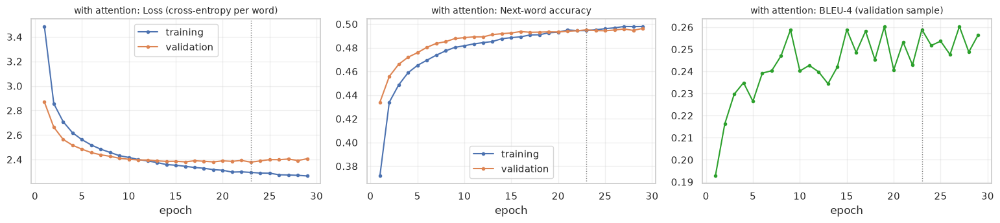

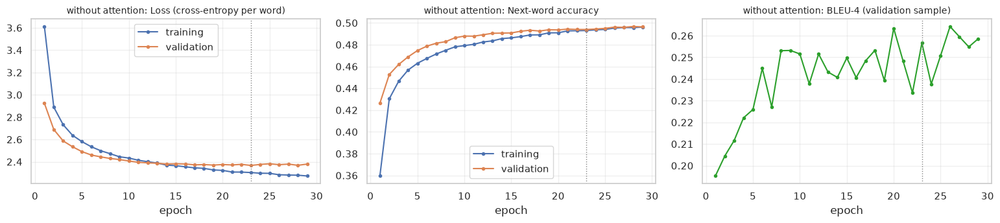

In [13]:
for name, hist in histories.items():
    evaluation.plot_history(hist, name)
    plt.show()

In [14]:
rows = []
for name, hist in histories.items():
    best = hist.loc[hist["val_loss"].idxmin()]
    rows.append({"model": name, "parameters": models_[name].count_params(), "epochs run": len(hist),
                 "best epoch": int(best["epoch"]), "train loss": best["loss"], "val loss": best["val_loss"],
                 "train word acc.": best["masked_accuracy"], "val word acc.": best["val_masked_accuracy"],
                 "val BLEU-4 (500 images)": best["val_bleu4"], "time (min)": times[name] / 60})
train_table = pd.DataFrame(rows).set_index("model")
display(train_table)

,parameters,epochs run,best epoch,train loss,val loss,train word acc.,val word acc.,val BLEU-4 (500 images),time (min)
model,,,,,,,,,
with attention,6209672,29,23,2.295,2.379,0.494,0.495,0.259,8.636
without attention,5947016,29,23,2.304,2.367,0.493,0.494,0.257,8.037


In [15]:
att, noatt = train_table.loc["with attention"], train_table.loc["without attention"]
gap = att["val loss"] - att["train loss"]
hist_att = histories["with attention"]
after = hist_att.loc[hist_att["epoch"] > att["best epoch"], "val_bleu4"]       # BLEU after the best loss epoch
display(Markdown(
    f"**Results.** With attention, the validation loss reaches **{att['val loss']:.3f}** at epoch {int(att['best epoch'])} "
    f"(next-word accuracy {att['val word acc.']:.3f}, BLEU-4 {att['val BLEU-4 (500 images)']:.3f} on the validation "
    f"sample). Without attention: {noatt['val loss']:.3f} at epoch {int(noatt['best epoch'])} (accuracy "
    f"{noatt['val word acc.']:.3f}, BLEU-4 {noatt['val BLEU-4 (500 images)']:.3f}). "
    f"At the kept epoch the validation loss of the attention model is {gap:+.3f} above its training loss. "
    + ("The validation loss stops improving while the training loss keeps going down: the model starts to learn "
       "the training captions by heart, and early stopping keeps the weights from before that point. "
       if histories["with attention"]["loss"].iloc[-1] < att["train loss"] else "")
    + (f"BLEU-4 on the validation sample still went up after the best loss epoch (up to {after.max():.3f}): the "
       "loss also counts the probability given to words that greedy decoding would not pick, so the two do not "
       "peak at the same time. Stopping on BLEU instead would need a larger validation sample to be reliable."
       if len(after) and after.max() > att["val BLEU-4 (500 images)"] + 0.005 else "")
))

**Results.** With attention, the validation loss reaches **2.379** at epoch 23 (next-word accuracy 0.495, BLEU-4 0.259 on the validation sample). Without attention: 2.367 at epoch 23 (accuracy 0.494, BLEU-4 0.257). At the kept epoch the validation loss of the attention model is +0.084 above its training loss. The validation loss stops improving while the training loss keeps going down: the model starts to learn the training captions by heart, and early stopping keeps the weights from before that point. 

**Reading the curves.** The training loss is measured with dropout switched on, so it is a little pessimistic
compared with the validation loss. When the validation loss goes back up while the training loss keeps falling,
the model is overfitting (variance side); early stopping keeps the weights of the best validation epoch. The
BLEU-4 curve is noisier than the loss because it is computed on 500 generated captions. Ways to push further are
listed in section 10 (more images, beam search, fine-tuning the CNN).

The choice between the two models is made on the **whole validation set** (2,000 images), with BLEU-4 on
generated captions, which is closer to the real use than the loss.

In [16]:
val_captions = {name: model.generate(m, feats["val"], vocab) for name, m in models_.items()}
val_bleu = pd.DataFrame({name: model.bleu(refs["val"], caps) for name, caps in val_captions.items()}).T
display(val_bleu)
chosen = val_bleu["BLEU-4"].idxmax()
captioner = models_[chosen]
print(f"Selected on validation: {chosen}")

,BLEU-1,BLEU-2,BLEU-3,BLEU-4
with attention,0.692,0.516,0.372,0.266
without attention,0.696,0.519,0.374,0.268


Selected on validation: without attention


### 6.1 How many training images?
The same model with attention is trained again on a growing part of the training images (the first eighth, a
quarter, half, then all of them) and scored on the same validation images. If the validation scores still
improve at the right of the curve, the model is limited by the amount of data (variance) and more images would
help. If the curve is flat, the model itself is the limit (bias). The vocabulary stays the one built on all the
training captions.

,epochs run,train loss,val loss,val BLEU-4
training images,,,,
9987,27,2.361,2.798,0.216
19975,25,2.338,2.611,0.240
39950,27,2.283,2.483,0.256
79901,29,2.295,2.379,0.266


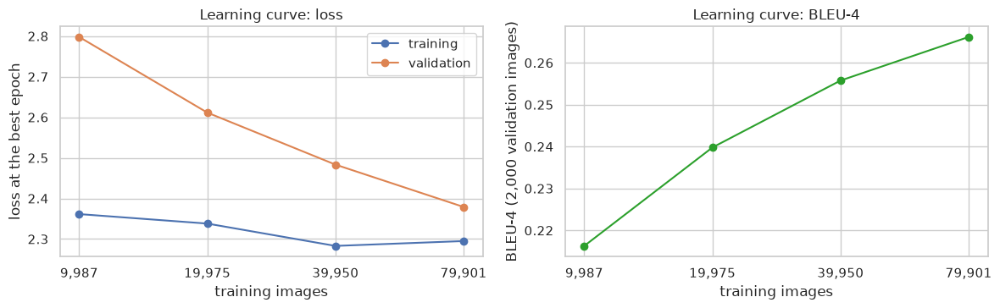

In [17]:
n_train = len(feats["train"])
curve_rows = []
for n in (n_train // 8, n_train // 4, n_train // 2, n_train):
    if n == n_train:
        m, hist = models_["with attention"], histories["with attention"]
    else:
        keras.utils.set_random_seed(config.SEED)
        m = model.build_captioner(vocab_size=len(vocab))
        keep = image_index["train"] < n                  # the sample order is random: the first n images
        batches = model.CaptionBatches(feats["train"][:n], tokens["train"][keep], image_index["train"][keep],
                                       one_per_image=True, **LOADER)
        hist = model.train(m, batches, model.CaptionBatches(feats["val"], tokens["val"], image_index["val"], **LOADER),
                           epochs=EPOCHS, patience=PATIENCE, verbose=0)
    best = hist.loc[hist["val_loss"].idxmin()]
    curve_rows.append({"training images": n, "epochs run": len(hist), "train loss": best["loss"],
                       "val loss": best["val_loss"],
                       "val BLEU-4": model.bleu(refs["val"], model.generate(m, feats["val"], vocab))["BLEU-4"]})
curve_df = pd.DataFrame(curve_rows).set_index("training images")
display(curve_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(curve_df.index, curve_df["train loss"], marker="o", label="training")
axes[0].plot(curve_df.index, curve_df["val loss"], marker="o", label="validation")
axes[0].set_ylabel("loss at the best epoch")
axes[0].legend()
axes[1].plot(curve_df.index, curve_df["val BLEU-4"], marker="o", color="tab:green")
axes[1].set_ylabel("BLEU-4 (2,000 validation images)")
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xticks(curve_df.index, [f"{n:,}" for n in curve_df.index])
    ax.minorticks_off()
    ax.set_xlabel("training images")
axes[0].set_title("Learning curve: loss")
axes[1].set_title("Learning curve: BLEU-4")
plt.tight_layout()
plt.show()

In [18]:
first, half, full = curve_df.iloc[0], curve_df.iloc[-2], curve_df.iloc[-1]
loss_drop = half["val loss"] - full["val loss"]
display(Markdown(
    f"**Results.** With {curve_df.index[0]:,} training images the model reaches a validation loss of "
    f"{first['val loss']:.3f} and BLEU-4 {first['val BLEU-4']:.3f}; with {curve_df.index[-1]:,} images, "
    f"{full['val loss']:.3f} and **{full['val BLEU-4']:.3f}**. Doubling the data from {curve_df.index[-2]:,} to "
    f"{curve_df.index[-1]:,} images lowers the validation loss by {loss_drop:.3f} and changes BLEU-4 by "
    f"{full['val BLEU-4'] - half['val BLEU-4']:+.3f}, and the gap between validation and training loss goes from "
    f"{first['val loss'] - first['train loss']:+.3f} to {full['val loss'] - full['train loss']:+.3f}. "
    + ("The validation loss is still going down at the right of the curve: more images would still help "
       "(variance side). BLEU-4, computed on generated captions, is a noisier measure and moves less regularly."
       if loss_drop > 0.02 else
       "The validation loss flattens: more images of the same kind would bring little, the model is the limit "
       "(bias side).")
))

**Results.** With 9,987 training images the model reaches a validation loss of 2.798 and BLEU-4 0.216; with 79,901 images, 2.379 and **0.266**. Doubling the data from 39,950 to 79,901 images lowers the validation loss by 0.104 and changes BLEU-4 by +0.010, and the gap between validation and training loss goes from +0.436 to +0.084. The validation loss is still going down at the right of the curve: more images would still help (variance side). BLEU-4, computed on generated captions, is a noisier measure and moves less regularly.

## 7. Evaluation on the test images

**BLEU** (bilingual evaluation understudy) is the standard score for generated text. It counts how many groups of
1, 2, 3 and 4 consecutive words (n-grams) of the generated caption also appear in one of the five reference
captions, and penalises captions that are too short. BLEU-1 measures the choice of words, BLEU-4 also the word
order and phrasing. The score goes from 0 to 1 and is computed over the whole test set (corpus BLEU).

To give a scale, we also score **human captions** the same way: for every test image, one of its five captions
is compared with the other four (four references instead of five, which lowers the score a little). People
describe the same scene in different words, so even a good description is far from a BLEU of 1.

In [19]:
test_captions = {name: model.generate(m, feats["test"], vocab) for name, m in models_.items()}
scores = pd.DataFrame({name: model.bleu(refs["test"], caps) for name, caps in test_captions.items()}).T
human = model.bleu([r[1:] for r in refs["test"]], [r[0] for r in refs["test"]])
scores.loc["human caption vs the 4 others"] = human
display(scores)

,BLEU-1,BLEU-2,BLEU-3,BLEU-4
with attention,0.693,0.512,0.366,0.260
without attention,0.694,0.512,0.366,0.258
human caption vs the 4 others,0.630,0.428,0.283,0.186


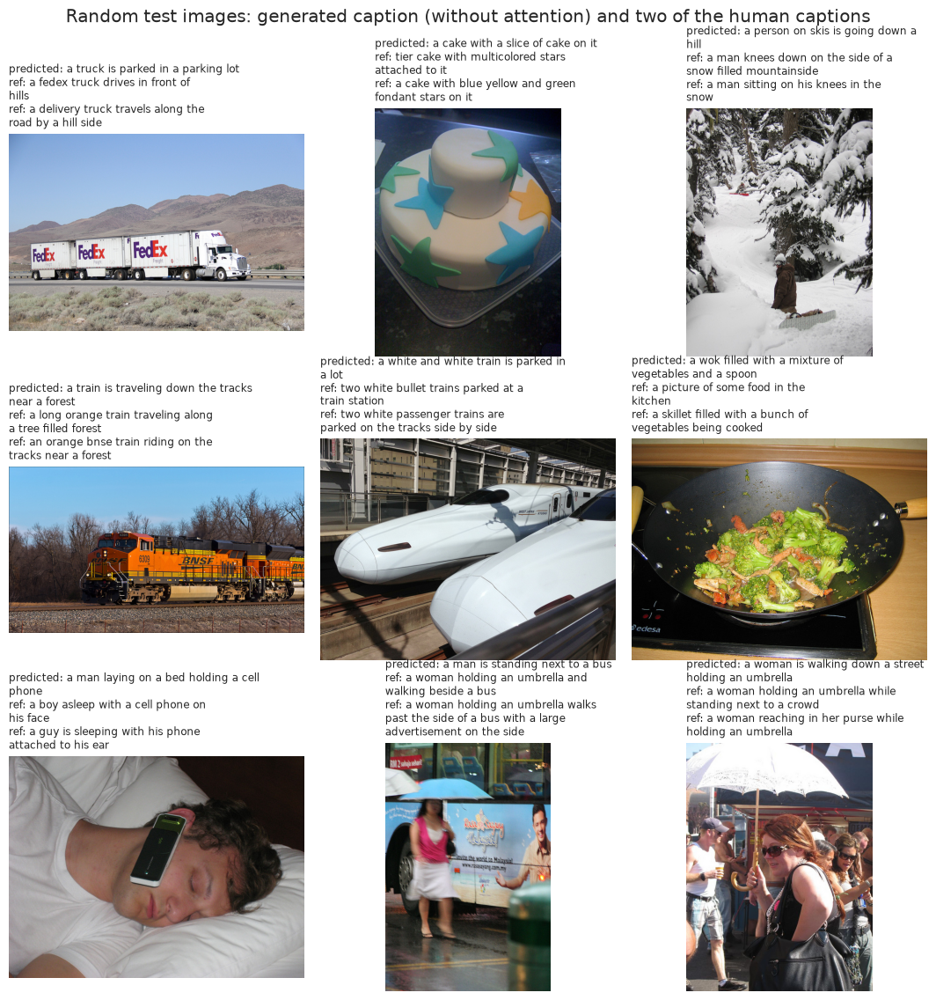

In [20]:
rng = np.random.default_rng(config.SEED)
pick = rng.choice(len(feats["test"]), 9, replace=False)
test_paths = images.loc[images["split"] == "test", "path"].to_numpy()
evaluation.show_captions([cls_data.read_rgb(test_paths[i]) for i in pick], [test_captions[chosen][i] for i in pick],
                         [refs["test"][i] for i in pick])
plt.suptitle(f"Random test images: generated caption ({chosen}) and two of the human captions", y=1.0)
plt.show()

### 7.1 Where does the model look?
For the model with attention, the weights over the 64 regions can be shown for each generated word. Bright areas
are the regions that weighed most in the choice of the word. The maps can be more spread out than one would
expect: each of the 64 InceptionV3 vectors comes from the last convolutional block, whose receptive field covers
most of the image, so the model does not need to look at the object itself to name it.

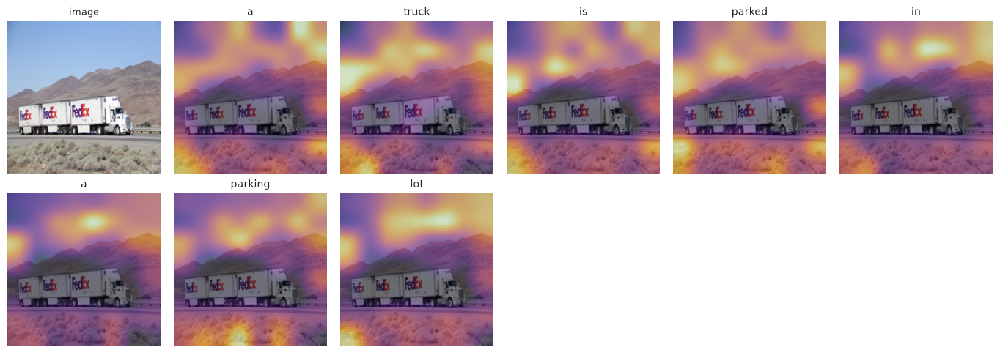

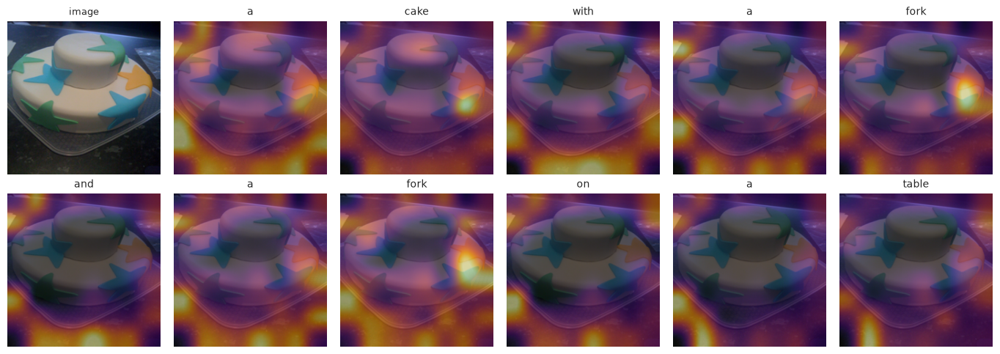

In [21]:
att_model = model.attention_model(models_["with attention"])
for i in pick[:2]:
    caption = test_captions["with attention"][i]
    weights = model.attention_maps(att_model, feats["test"][i:i + 1], [caption], vocab)[0]
    evaluation.show_attention(features.load_image(test_paths[i]), caption, weights)
    plt.show()

In [22]:
gen_words = Counter(w for c in test_captions[chosen] for w in c.split())
ref_words = Counter(w for rs in refs["test"] for r in rs[:1] for w in r.split())
train_set = {c for rs in refs["train"] for c in rs}
copied = np.mean([c in train_set for c in test_captions[chosen]])
lengths_gen = np.mean([len(c.split()) for c in test_captions[chosen]])
lengths_ref = np.mean([len(r.split()) for rs in refs["test"] for r in rs])
best = scores.loc[chosen]
display(Markdown(
    f"**Results.** On the {len(feats['test']):,} test images, the selected model ({chosen}) reaches "
    f"BLEU-1 **{best['BLEU-1']:.3f}** and BLEU-4 **{best['BLEU-4']:.3f}**; "
    + ", ".join(f"{n}: BLEU-4 {scores.loc[n, 'BLEU-4']:.3f}" for n in models_ if n != chosen)
    + f". Human captions scored the same way get BLEU-4 {human['BLEU-4']:.3f}. "
    + ("The two models are within 0.01 of each other: with these features, attention brings little on BLEU, but it "
       "makes the choices of the model visible (section 7.1). "
       if abs(scores.loc["with attention", "BLEU-4"] - scores.loc["without attention", "BLEU-4"]) < 0.01 else "")
    + f"The generated captions use {len(gen_words):,} distinct words, against {len(ref_words):,} in one human caption "
    "per image" + (": greedy decoding prefers frequent words and common phrasings. " if len(gen_words) < len(ref_words)
                   else ". ") + f"{copied:.0%} of the generated captions "
    f"are word for word a training caption. Mean length: {lengths_gen:.1f} words, against {lengths_ref:.1f} for "
    "the human captions."
))

**Results.** On the 2,000 test images, the selected model (without attention) reaches BLEU-1 **0.694** and BLEU-4 **0.258**; with attention: BLEU-4 0.260. Human captions scored the same way get BLEU-4 0.186. The two models are within 0.01 of each other: with these features, attention brings little on BLEU, but it makes the choices of the model visible (section 7.1). The generated captions use 488 distinct words, against 2,279 in one human caption per image: greedy decoding prefers frequent words and common phrasings. 33% of the generated captions are word for word a training caption. Mean length: 9.6 words, against 10.5 for the human captions.

## 8. Case study: noisy photos, denoising and caption quality

Deliverable 2 measured the denoiser with pixel scores (PSNR, SSIM). What matters for TouNum is the caption.
Here we measure how noise changes the captions, and whether denoising first gives them back.

### 8.1 Stronger noise on the test images
We take test images, add the synthetic colour noise of deliverable 2 (Gaussian noise on the colour channels, then
JPEG quality 95) at levels well above the real TouNum noise, and caption three versions of each image: the noisy
image, the image denoised by the autoencoder of deliverable 2, and the image processed by the pipeline rule
saved by deliverable 2.

In [23]:
denoiser_path = dn_config.MODELS_DIR / "denoiser.keras"
if QUICK and not denoiser_path.exists():             # deliverable 2 only ran in quick mode
    denoiser_path = Path(tempfile.gettempdir()) / "tounum_quick" / "denoiser.keras"
denoiser = keras.models.load_model(denoiser_path)
dn_settings = json.loads(denoiser_path.with_suffix(".json").read_text())
NOISE_THRESHOLD = float(dn_settings["noise_threshold"])
LEVELS = (0, 10, 20)
case_paths = test_paths[:N_CASE]
case_refs = refs["test"][:N_CASE]


def noisy_versions(paths, sigma, seed):
    """Prepared 299x299 inputs for the noisy, denoised and rule versions of each image, and the rule decisions."""
    def make_noisy(args):
        k, p = args
        img = cls_data.read_rgb(p)
        return dn_data.add_noise(img, sigma, np.random.default_rng(seed + k)) if sigma else img

    with ThreadPoolExecutor(8) as ex:
        noisy = list(ex.map(make_noisy, enumerate(paths)))
        estimates = list(ex.map(dn_data.estimate_noise, noisy))
    denoised = [dn_modeling.denoise(denoiser, img) for img in noisy]
    rule = [d if e >= NOISE_THRESHOLD else n for n, d, e in zip(noisy, denoised, estimates)]
    prep = lambda imgs: np.stack([features.prepare(im) for im in imgs])
    return {"noisy": prep(noisy), "denoised": prep(denoised), "pipeline rule": prep(rule)}, np.array(estimates)


t0 = time.perf_counter()
case_rows, case_examples = [], {}
for sigma in LEVELS:
    versions, est = noisy_versions(case_paths, sigma, seed=config.SEED + sigma)
    for variant, inputs in versions.items():
        caps = model.generate(captioner, features.encode(encoder, inputs), vocab)
        case_rows.append({"sigma": sigma, "input": variant, **model.bleu(case_refs, caps),
                          "denoised share": float(np.mean(est >= NOISE_THRESHOLD)) if variant == "pipeline rule"
                          else float(variant == "denoised")})
        case_examples[(sigma, variant)] = (inputs[:6], caps[:6])
case_df = pd.DataFrame(case_rows)
display(case_df.pivot(index="input", columns="sigma", values="BLEU-4").round(3))
print(f"{len(case_paths)} test images x {len(LEVELS)} noise levels x 3 versions in {time.perf_counter() - t0:.0f} s")

sigma,0,10,20
input,,,
denoised,0.257,0.257,0.263
noisy,0.257,0.258,0.255
pipeline rule,0.258,0.257,0.263


1000 test images x 3 noise levels x 3 versions in 192 s


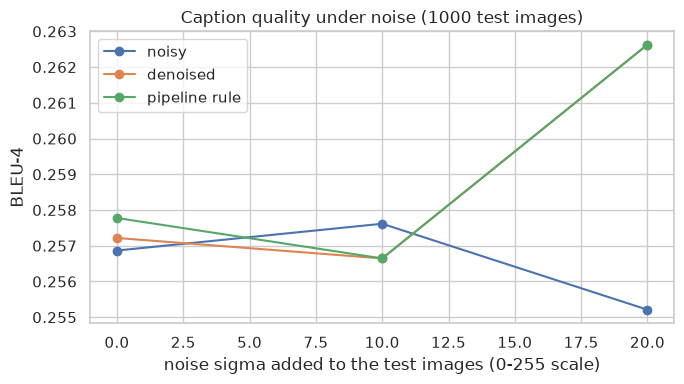

In [24]:
fig, ax = plt.subplots(figsize=(7, 4))
for variant, grp in case_df.groupby("input", sort=False):
    ax.plot(grp["sigma"], grp["BLEU-4"], marker="o", label=variant)
ax.set_xlabel("noise sigma added to the test images (0-255 scale)")
ax.set_ylabel("BLEU-4")
ax.set_title(f"Caption quality under noise ({len(case_paths)} test images)")
ax.legend()
plt.tight_layout()
plt.show()

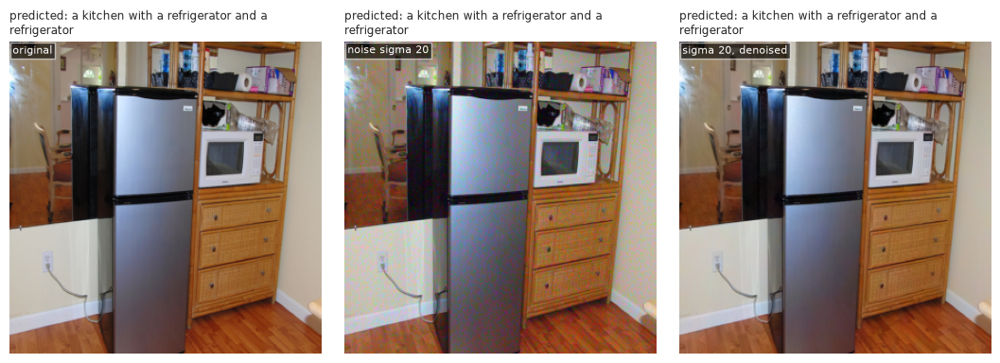

In [25]:
k, top = 3, LEVELS[-1]
imgs = [case_examples[(0, "noisy")][0][k], case_examples[(top, "noisy")][0][k], case_examples[(top, "denoised")][0][k]]
caps = [case_examples[(0, "noisy")][1][k], case_examples[(top, "noisy")][1][k], case_examples[(top, "denoised")][1][k]]
evaluation.show_captions(imgs, caps, cols=3, titles=["original", f"noise sigma {top}", f"sigma {top}, denoised"])
plt.show()

In [26]:
piv = case_df.pivot(index="input", columns="sigma", values="BLEU-4")
clean_rule = case_df.query("sigma == 0 and input == 'pipeline rule'").iloc[0]
drop = piv.loc["noisy", 0] - piv.loc["noisy", top]
display(Markdown(
    f"**Results.** On clean images the model reaches BLEU-4 {piv.loc['noisy', 0]:.3f}. With noise, BLEU-4 on the "
    "noisy images and on the same images denoised first is "
    + "; ".join(f"{piv.loc['noisy', s]:.3f} and {piv.loc['denoised', s]:.3f} at sigma {s}" for s in LEVELS[1:]) + ". "
    + ("Even strong colour noise changes BLEU-4 by less than 0.01: InceptionV3 relies mostly on shapes and "
       "textures, which this noise leaves untouched, so for captioning the denoiser matters little. "
       if abs(drop) < 0.01 else
       f"Noise of sigma {top} costs {drop:.3f} of BLEU-4. ")
    + f"On clean images the pipeline rule denoises {clean_rule['denoised share']:.0%} of them and scores "
    f"{piv.loc['pipeline rule', 0]:.3f}, against {piv.loc['noisy', 0]:.3f} without any denoising."
))

**Results.** On clean images the model reaches BLEU-4 0.257. With noise, BLEU-4 on the noisy images and on the same images denoised first is 0.258 and 0.257 at sigma 10; 0.255 and 0.263 at sigma 20. Even strong colour noise changes BLEU-4 by less than 0.01: InceptionV3 relies mostly on shapes and textures, which this noise leaves untouched, so for captioning the denoiser matters little. On clean images the pipeline rule denoises 59% of them and scores 0.258, against 0.257 without any denoising.

### 8.2 The noisy photos provided by TouNum
These are the images of deliverable 2. Their clean originals and the five COCO captions of each are known, and
none of them was used to train the captioning model (section 2). The denoiser of deliverable 2 was fine-tuned on
part of them, so we only use its 50 test images here. We caption the original, the noisy file and the noisy file
after the pipeline rule.

In [27]:
noisy_paths = [p for p in dn_data.extract_noisy() if p.name in set(dn_settings["test_files"])]
noisy_imgs, noisy_info = dn_data.load_noisy(noisy_paths)
original_imgs = dn_data.load_originals(noisy_paths)
coco_ids = originals.set_index("file").loc[noisy_info["file"], "coco_id"].to_numpy()
all_train_caps = data.load_captions("train2017")
tounum_refs = [[" ".join(data.clean_caption(c).split()[1:-1]) for c in all_train_caps.loc[all_train_caps["image_id"] == i, "caption"]]
               for i in coco_ids]
rule_imgs = [dn_modeling.denoise(denoiser, im) if s >= NOISE_THRESHOLD else im
             for im, s in zip(noisy_imgs, noisy_info["noise_sigma"])]
tounum_caps = {}
for variant, imgs in (("clean original", original_imgs), ("noisy file", noisy_imgs), ("pipeline rule", rule_imgs)):
    tounum_caps[variant] = model.generate(captioner, features.encode(encoder, np.stack([features.prepare(im) for im in imgs])), vocab)
tounum_scores = pd.DataFrame({v: model.bleu(tounum_refs, c) for v, c in tounum_caps.items()}).T
display(tounum_scores)
changed = np.mean([a != b for a, b in zip(tounum_caps["clean original"], tounum_caps["noisy file"])])

,BLEU-1,BLEU-2,BLEU-3,BLEU-4
clean original,0.718,0.555,0.406,0.299
noisy file,0.730,0.570,0.418,0.310
pipeline rule,0.731,0.571,0.418,0.309


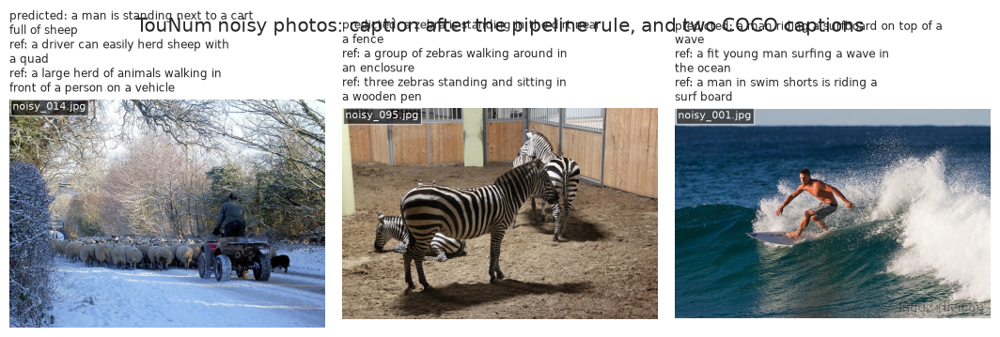

**Results.** On the 50 TouNum test photos, BLEU-4 is 0.299 on the clean originals, 0.310 on the noisy files and 0.309 after the pipeline rule. The noise of these files is light (deliverable 2): 18% of the captions change between the original and the noisy file. With so few images and such light noise, small differences in BLEU are within the noise of the measure; section 8.1 shows the effect of stronger noise.

In [28]:
worst = noisy_info["noise_sigma"].nlargest(3).index
evaluation.show_captions([noisy_imgs[i] for i in worst], [tounum_caps["pipeline rule"][i] for i in worst],
                         [tounum_refs[i] for i in worst], titles=[noisy_info["file"][i] for i in worst])
plt.suptitle("TouNum noisy photos: caption after the pipeline rule, and two COCO captions", y=1.0)
plt.show()

display(Markdown(
    f"**Results.** On the {len(noisy_imgs)} TouNum test photos, BLEU-4 is "
    f"{tounum_scores.loc['clean original', 'BLEU-4']:.3f} on the clean originals, {tounum_scores.loc['noisy file', 'BLEU-4']:.3f} on the noisy files and "
    f"{tounum_scores.loc['pipeline rule', 'BLEU-4']:.3f} after the pipeline rule. The noise of these files is light "
    f"(deliverable 2): {changed:.0%} of the captions change between the original and the noisy file. "
    "With so few images and such light noise, small differences in BLEU are within the noise of the measure; "
    "section 8.1 shows the effect of stronger noise."
))

## 9. The complete workflow

The three deliverables are now chained in `src/tounum_caption/pipeline.py`. For every image file of a folder:

1. **Filter** (deliverable 1): the production classifier `models/photo_classifier.keras` gives P(photo) on the
   image resized to 128 x 128. Images below 0.5 are set aside without a caption.
2. **Pre-process** (deliverable 2): the noise level of each photo is estimated without reference (Immerkaer).
   If it reaches the threshold saved in `models/denoiser.json`, the photo is denoised at full size by
   `models/denoiser.keras`.
3. **Caption** (deliverable 3): InceptionV3 features, then greedy decoding with `models/captioner.keras` and the
   vocabulary saved in `models/captioner.json`.

The result is a table with one row per file. The same code runs from the command line:
`uv run python scripts/caption_folder.py <folder> --out captions.csv`.

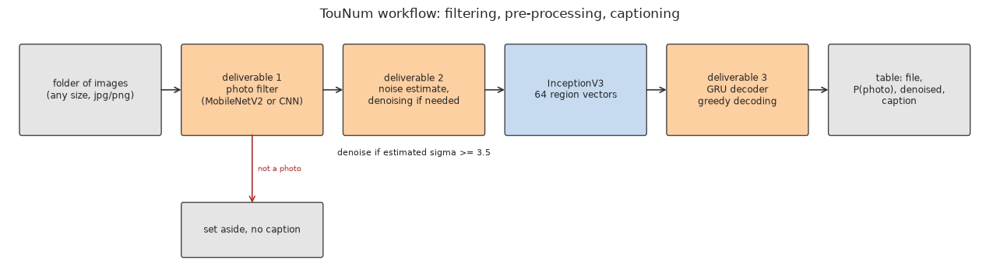

    def run(self, inputs, chunk: int = 64) -> pd.DataFrame:
        """Run the workflow on a folder (or a list of image files).

        Returns one row per file: file, path, p_photo, is_photo, noise_sigma, denoised, caption.
        Non-photos get no caption; unreadable files are reported in the `caption` column.
        """
        paths = list_images(inputs) if isinstance(inputs, (str, Path)) else [Path(p) for p in inputs]
        rows, photo_feats, photo_rows = [], [], []
        t = {"read + filter": 0.0, "denoise": 0.0, "encode": 0.0, "caption": 0.0}
        for start in range(0, len(paths), chunk):
            t0 = time.perf_counter()
            images, batch_rows = [], []
            for p in paths[start:start + chunk]:
                row = {"file": p.name, "path": str(p), "p_photo": np.nan, "is_photo": False,
                       "noise_sigma": np.nan, "denoised": False, "caption": ""}
                try:
                    images.append(cls_data.read_rgb(p))
           

In [29]:
evaluation.draw_workflow(NOISE_THRESHOLD)
plt.show()
print(inspect.getsource(pipeline.CaptionPipeline.run))

### 9.1 Saving the captioning model
The captioner is saved with its settings and vocabulary. In quick mode the models of deliverables 1 and 2 are
copied next to it, so the quick run never reads or writes `models/`.

In [30]:
SAVE_DIR.mkdir(parents=True, exist_ok=True)
captioner.save(SAVE_DIR / "captioner.keras")
settings = {"model": chosen, "max_len": config.MAX_LEN, "encoder": "InceptionV3 (ImageNet), 299x299, 8x8x2048",
            "vocab": vocab}
(SAVE_DIR / "captioner.json").write_text(json.dumps(settings))
reloaded = keras.models.load_model(SAVE_DIR / "captioner.keras")
assert model.generate(reloaded, feats["test"][:16], vocab) == test_captions[chosen][:16]
if QUICK:
    classifier_path = cls_config.MODELS_DIR / "photo_classifier.keras"
    if not classifier_path.exists():
        classifier_path = Path(tempfile.gettempdir()) / "tounum_quick" / "photo_classifier.keras"
    for src in (classifier_path, denoiser_path, denoiser_path.with_suffix(".json")):
        if src.parent != SAVE_DIR:
            shutil.copy(src, SAVE_DIR / src.name)
shown_dir = SAVE_DIR.relative_to(config.PROJECT_ROOT) if SAVE_DIR.is_relative_to(config.PROJECT_ROOT) else SAVE_DIR
print(f"Saved {shown_dir}/captioner.keras ({(SAVE_DIR / 'captioner.keras').stat().st_size / 1e6:.1f} MB) and "
      f"{shown_dir}/captioner.json ({len(vocab)} words), reload checked.")

Saved models/captioner.keras (71.4 MB) and models/captioner.json (5000 words), reload checked.


### 9.2 A demo folder that looks like a TouNum archive
To test the whole chain, we build a folder that mixes what TouNum receives: clean photos (COCO test images),
photos with strong noise, the noisy photos of deliverable 2, and non-photos from the extended test set of
deliverable 1 (paintings, diagrams, scanned text, sketches). None of these images was used to train any of the
three models. The file names start with the true type, so the decisions of the pipeline can be checked.

In [31]:
DEMO_DIR = config.DATA_DIR / "demo"
shutil.rmtree(DEMO_DIR, ignore_errors=True)
DEMO_DIR.mkdir(parents=True)
for k, p in enumerate(test_paths[-6:]):
    shutil.copy(p, DEMO_DIR / f"photo_{k}_{Path(p).name}")
rng = np.random.default_rng(config.SEED)
for k, p in enumerate(test_paths[-8:-6]):
    noisy = dn_data.add_noise(cls_data.read_rgb(p), 15, rng)
    Image.fromarray(noisy).save(DEMO_DIR / f"photo_noisy_{k}_{Path(p).name}", quality=95, subsampling=0)
for i in noisy_info["noise_sigma"].nlargest(2).index:
    shutil.copy(noisy_paths[i], DEMO_DIR / f"photo_tounum_{noisy_info['file'][i]}")
cls_meta = pd.read_csv(cls_config.CACHE_DIR / "meta.csv")
non_photos = cls_meta[(cls_meta["split"] == "ext") & (cls_meta["label"] == 0)].groupby("source").sample(2, random_state=config.SEED)
for _, r in non_photos.iterrows():
    name, prefix = Path(r["path"]).name, r["source"].lower()
    shutil.copy(cls_config.PROJECT_ROOT / r["path"], DEMO_DIR / (name if name.lower().startswith(prefix) else f"{prefix}_{name}"))
print(f"{len(list(DEMO_DIR.iterdir()))} files in {DEMO_DIR.relative_to(config.PROJECT_ROOT)}")

18 files in data/demo


In [32]:
pipe = pipeline.CaptionPipeline.load(SAVE_DIR, encoder=encoder)
t0 = time.perf_counter()
results = pipe.run(DEMO_DIR)
elapsed = time.perf_counter() - t0
display(results.drop(columns="path"))

,file,p_photo,is_photo,noise_sigma,denoised,caption
0,painting_01150.jpg,1.140e-03,False,NaN,False,
1,painting_09787.jpg,2.411e-03,False,NaN,False,
2,photo_0_000000092091.jpg,9.943e-01,True,6.888,True,a little boy is holding a baby in his arms
3,photo_1_000000473118.jpg,9.955e-01,True,3.378,False,a man riding a skateboard down a ramp
4,photo_2_000000423971.jpg,9.977e-01,True,1.199,False,a toilet with a toilet seat and a seat
5,photo_3_000000386277.jpg,9.769e-01,True,2.350,False,a orange is sitting on a tree branch
6,photo_4_000000299609.jpg,9.868e-01,True,3.983,True,a horse is grazing in a field of grass
7,photo_5_000000366611.jpg,9.990e-01,True,13.932,True,a dog is running in the grass with a frisbee
8,photo_noisy_0_000000453841.jpg,9.862e-01,True,12.401,True,a street light with a red light on
9,photo_noisy_1_000000321557.jpg,9.691e-01,True,15.164,True,a motorcycle parked in a parking lot with a man on the side of the road


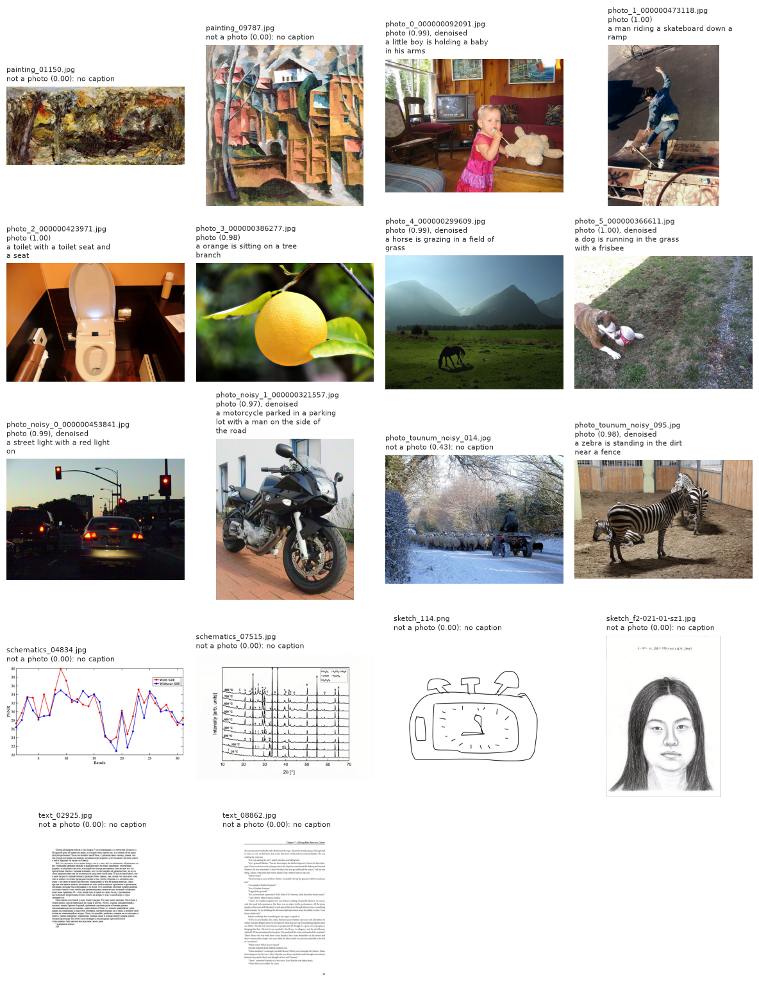

In [33]:
evaluation.show_gallery(results, n=len(results), cols=4)
plt.show()

In [34]:
truth = results["file"].str.startswith("photo")
display(Markdown(
    f"**Results.** {len(results)} files processed in {elapsed:.1f} s ({elapsed / len(results):.2f} s per image, "
    f"model loading excluded). The filter keeps **{int(results['is_photo'].sum())}** images as photos; "
    f"{int((results['is_photo'] == truth).sum())} of the {len(results)} decisions match the true type. "
    f"{int(results['denoised'].sum())} photos were denoised before captioning. Time per step (s): "
    + ", ".join(f"{k} {v:.1f}" for k, v in pipe.timings.items()) + "."
))

**Results.** 18 files processed in 6.7 s (0.37 s per image, model loading excluded). The filter keeps **9** images as photos; 17 of the 18 decisions match the true type. 6 photos were denoised before captioning. Time per step (s): read + filter 3.1, denoise 0.3, encode 3.1, caption 0.2.

## 10. Conclusion, limits and next steps

In [35]:
display(Markdown(
    f"**Summary.** Captioning model: InceptionV3 (frozen) + GRU decoder {chosen}, "
    f"{captioner.count_params():,} trained parameters, chosen on the validation set. Test BLEU-1 "
    f"{scores.loc[chosen, 'BLEU-1']:.3f}, BLEU-4 **{scores.loc[chosen, 'BLEU-4']:.3f}** on {len(feats['test']):,} "
    f"images (human captions: {human['BLEU-4']:.3f}). Under colour noise of sigma {top}, BLEU-4 is "
    f"{piv.loc['noisy', top]:.3f} without denoising and {piv.loc['denoised', top]:.3f} with it; on the TouNum test "
    f"photos, {tounum_scores.loc['noisy file', 'BLEU-4']:.3f} on the noisy files and "
    f"{tounum_scores.loc['pipeline rule', 'BLEU-4']:.3f} after the pipeline rule. The complete workflow processed "
    f"the demo folder at {elapsed / len(results):.2f} s per image."
))

**Summary.** Captioning model: InceptionV3 (frozen) + GRU decoder without attention, 5,947,016 trained parameters, chosen on the validation set. Test BLEU-1 0.694, BLEU-4 **0.258** on 2,000 images (human captions: 0.186). Under colour noise of sigma 20, BLEU-4 is 0.255 without denoising and 0.263 with it; on the TouNum test photos, 0.310 on the noisy files and 0.309 after the pipeline rule. The complete workflow processed the demo folder at 0.37 s per image.

### What was built
1. A **reproducible data pipeline** for MS COCO 2017: sampling, download of the sampled images only, caption
   cleaning, vocabulary and encoding.
2. An **image pre-processing step** based on a CNN pre-trained for classification (InceptionV3), with a feature
   cache that makes training fast.
3. Two **captioning models** (CNN encoder + GRU decoder, with and without attention) trained with teacher
   forcing, with training curves, a learning curve on the number of images, BLEU scores on unseen images and
   attention maps. The one with the better validation BLEU-4 is saved for the workflow.
4. A **case study** that links deliverable 2 to the end result: the effect of noise and denoising on captions.
5. The **complete workflow** (filter, denoise, caption) as reusable code, a command line script and the cell below.

### Limits
- **Greedy decoding** picks the most likely word at each step. The captions tend to be generic and can reuse
  frequent phrasings of the training set (measured in section 7). Beam search would explore several candidate
  sentences.
- **Training data**: 80,000 COCO images. COCO shows everyday scenes; TouNum archives may contain other subjects
  (old documents, technical objects) that the model has never seen and will describe with the closest COCO words.
- **Frozen CNN**: InceptionV3 is not fine-tuned. Fine-tuning its last blocks on the captions usually helps, at a
  much higher training cost.
- **BLEU** rewards word overlap with five human captions. A correct caption with other words gets a low score, so
  BLEU is a comparison tool between models, not an absolute measure of quality.
- **Errors add up along the chain**: a painting accepted by the filter gets a caption as if it were a photo, and
  a photo rejected by the filter gets none.

### Next steps
- Beam search decoding and a larger training sample (all of COCO 2017);
- fine-tuning the last InceptionV3 blocks, or a more recent encoder;
- a small set of TouNum images captioned by hand, to measure quality on their real archives;
- logging the pipeline decisions in production (share of photos, share denoised, caption length) to catch drift.

### Running the workflow on a new folder (presentation day)
This last cell is self-contained: it loads the saved models and runs the whole workflow. Change `INPUT_DIR` and
run this cell only; the rest of the notebook does not need to be run again.

,file,p_photo,is_photo,noise_sigma,denoised,caption
0,painting_01150.jpg,1.140e-03,False,NaN,False,
1,painting_09787.jpg,2.411e-03,False,NaN,False,
2,photo_0_000000092091.jpg,9.943e-01,True,6.888,True,a little boy is holding a baby in his arms
3,photo_1_000000473118.jpg,9.955e-01,True,3.378,False,a man riding a skateboard down a ramp
4,photo_2_000000423971.jpg,9.977e-01,True,1.199,False,a toilet with a toilet seat and a seat
5,photo_3_000000386277.jpg,9.769e-01,True,2.350,False,a orange is sitting on a tree branch
6,photo_4_000000299609.jpg,9.868e-01,True,3.983,True,a horse is grazing in a field of grass
7,photo_5_000000366611.jpg,9.990e-01,True,13.932,True,a dog is running in the grass with a frisbee
8,photo_noisy_0_000000453841.jpg,9.862e-01,True,12.401,True,a street light with a red light on
9,photo_noisy_1_000000321557.jpg,9.691e-01,True,15.164,True,a motorcycle parked in a parking lot with a man on the side of the road


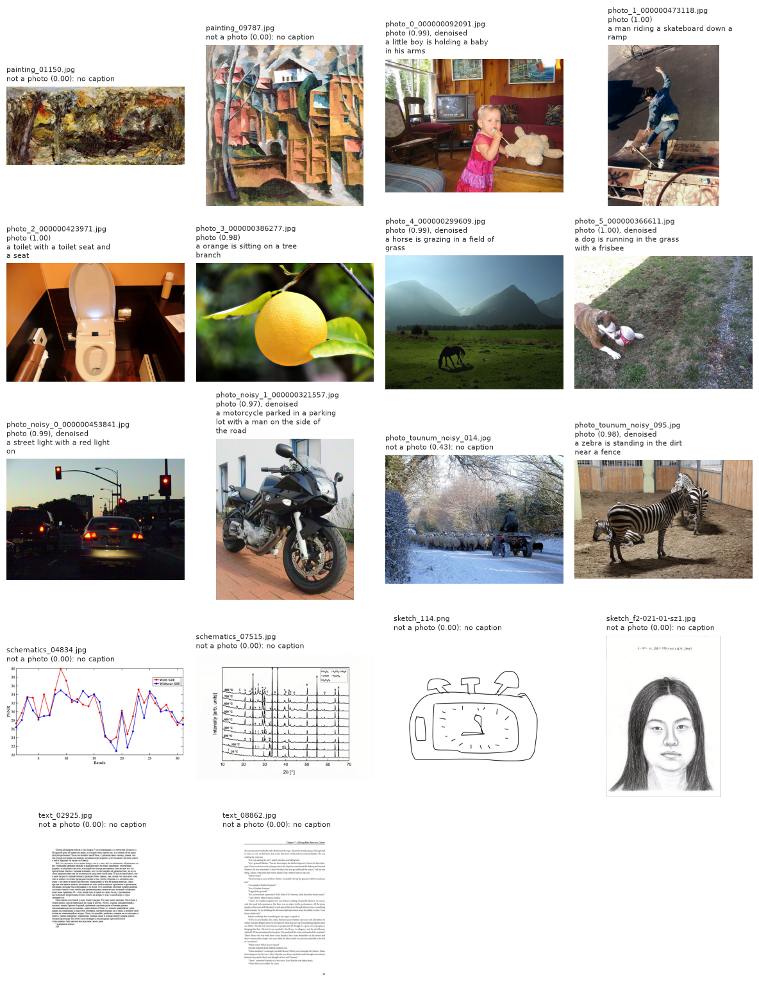

In [36]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import tounum_gpu
tounum_gpu.setup()
import matplotlib.pyplot as plt
from IPython.display import display
from tounum_caption import evaluation
from tounum_caption.pipeline import CaptionPipeline

INPUT_DIR = ROOT / "data" / "demo"                      # <- the folder to caption
MODELS_DIR = Path(os.environ.get("TOUNUM_MODELS_DIR", ROOT / "models"))   # the quick test run uses a temporary copy

pipe = CaptionPipeline.load(MODELS_DIR)
results = pipe.run(INPUT_DIR)
results.drop(columns="path").to_csv(ROOT / "data" / "captions.csv", index=False)
display(results.drop(columns="path"))
evaluation.show_gallery(results, n=24, cols=4)              # the first 24 images; the table lists them all
plt.show()